In [1]:
%reload_ext autoreload
%autoreload 2
import sys, os
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Add project root to path
project_root = '/sdf/group/neutrino/pgranger/larnd-sim-jax/src'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

%cd /sdf/group/neutrino/pgranger/larnd-sim-jax

from larndsim.consts_jax import build_params_class, load_detector_properties, load_lut
from larndsim.losses_jax import llhd_loss, adc2charge, mse_adc
from optimize.strategies import LUTSimulation, LUTProbabilisticSimulation, ProbabilisticLossStrategy, CollapsedProbabilisticLossStrategy
from optimize.dataio import TracksDataset, DataLoader
from optimize.ranges import ranges

import optimize.strategies
import logging
logging.getLogger(optimize.strategies.__name__).setLevel(logging.WARNING)

/sdf/home/p/pgranger/.local/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


/sdf/group/neutrino/pgranger/larnd-sim-jax


In [2]:
# --- Configuration ---

# INPUT_FILE = 'prepared_data/input_1.h5'
# INPUT_FILE = '/sdf/data/neutrino/cyifan/diffsim_input/true_ending_muon_edep_5cm_vol2cm_range_0.2-cm_CSDA.h5'
INPUT_FILE = '/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5'
LUT_FILE = 'src/larndsim/detector_properties/response_44.npy'
DET_PROPS = 'src/larndsim/detector_properties/module0.yaml'
PIXEL_LAYOUTS = 'src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml'

# Parameters to optimize (and their ranges)

RELEVANT_PARAMS = ['Ab', 'kb', 'lifetime', 'tran_diff', 'long_diff', 'eField', 'shift_x', 'shift_y', 'shift_z']

# Simulation Settings
ELECTRON_SAMPLING_RESOLUTION = 0.01
NUMBER_PIX_NEIGHBORS = 4
SIGNAL_LENGTH = 150

# --- Setup Parameters ---

ParamsClass = build_params_class(RELEVANT_PARAMS)
ref_params = load_detector_properties(ParamsClass, DET_PROPS, PIXEL_LAYOUTS)
ref_params = ref_params.replace(
    electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION,
    number_pix_neighbors=NUMBER_PIX_NEIGHBORS,
    signal_length=SIGNAL_LENGTH,
    time_window=SIGNAL_LENGTH,
    # RESET_NOISE_CHARGE = 0.1,
    #DISCRIMINATION_THRESHOLD = 5000,
    # UNCORRELATED_NOISE_CHARGE = 0.1,
    # Ensure noise params are zero for deterministic checks if needed, but llhd handles noise in prob
)

response, ref_params = load_lut(LUT_FILE, ref_params)

# Set nominal values
initial_values = {p: ranges[p]['nom'] for p in RELEVANT_PARAMS}
current_params = ref_params.replace(**initial_values)

print("Parameters initialized.")

INFO:larndsim.consts_jax:Loading response from numpy array
Could not load symbol cuFuncGetName. Error: /.singularity.d/libs/libcuda.so.1: undefined symbol: cuFuncGetName


Parameters initialized.


In [3]:
target_strategy = LUTSimulation(response)

In [4]:
# --- Load Data ---

dataset = TracksDataset(filename=INPUT_FILE, ntrack=-1, max_nbatch=20, max_batch_len=3500,
                        electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION)
dataloader = DataLoader(dataset, batch_size=1)

# Get one batch
tracks_batch = dataloader[0]
track_fields = dataset.get_track_fields()


tracks = jax.device_put(tracks_batch.reshape(-1, len(track_fields)))

INFO:optimize.dataio:-- The used data includes a total track length of 69999.82739257812 cm.
INFO:optimize.dataio:-- The maximum batch track length is 3500 cm.
INFO:optimize.dataio:-- The number of batches is 20.
INFO:optimize.dataio:Padding sequences with padding value: 0


In [5]:
print("Nb segments in batch:", tracks.shape[0])

Nb segments in batch: 351728


In [6]:
from larndsim.sim_jax import simulate_wfs

SIGNAL_LENGTH = 120
NUMBER_PIX_NEIGHBORS = 2

ParamsClass = build_params_class({})
ref_params = load_detector_properties(ParamsClass, DET_PROPS, PIXEL_LAYOUTS)
ref_params = ref_params.replace(
    electron_sampling_resolution=ELECTRON_SAMPLING_RESOLUTION,
    number_pix_neighbors=NUMBER_PIX_NEIGHBORS,
    signal_length=SIGNAL_LENGTH,
    time_window=SIGNAL_LENGTH,
    # RESET_NOISE_CHARGE = 0.1,
    #DISCRIMINATION_THRESHOLD = 5000,
    # UNCORRELATED_NOISE_CHARGE = 0.1,
    # Ensure noise params are zero for deterministic checks if needed, but llhd handles noise in prob
)

response, ref_params = load_lut(LUT_FILE, ref_params)

#Warmup JIT
print("Warming up JIT compilation...")
_ = simulate_wfs(ref_params, response, tracks, track_fields)
print("JIT compilation done.")

%timeit -n 10 -r 3simulate_wfs(ref_params, response, tracks, track_fields)[0].block_until_ready()

INFO:larndsim.consts_jax:Loading response from numpy array
2026-03-19 10:47:32.549108: W external/xla/xla/tsl/framework/bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.43GiB (rounded to 1531710208)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
2026-03-19 10:47:32.549225: W external/xla/xla/tsl/framework/bfc_allocator.cc:512] ************************************_______________*****************______**********________________
E0319 10:47:32.549250  552579 pjrt_stream_executor_client.cc:2916] Execution of replica 0 failed: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 1531710000 bytes. [tf-allocator-allocation-error='']


ValueError: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 1531710000 bytes.

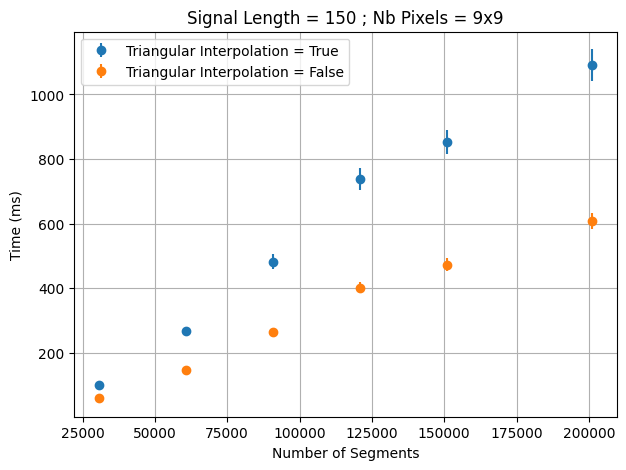

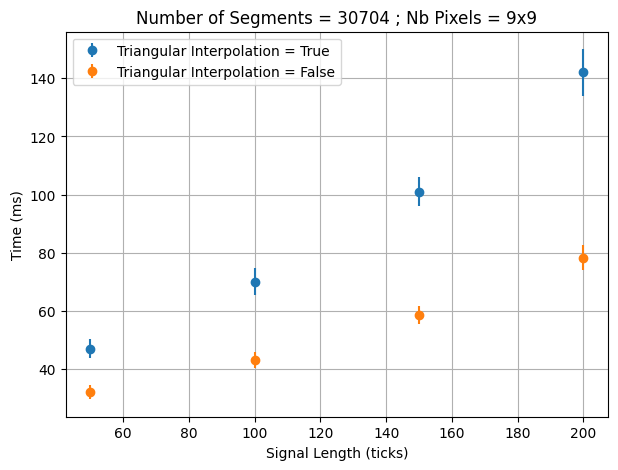

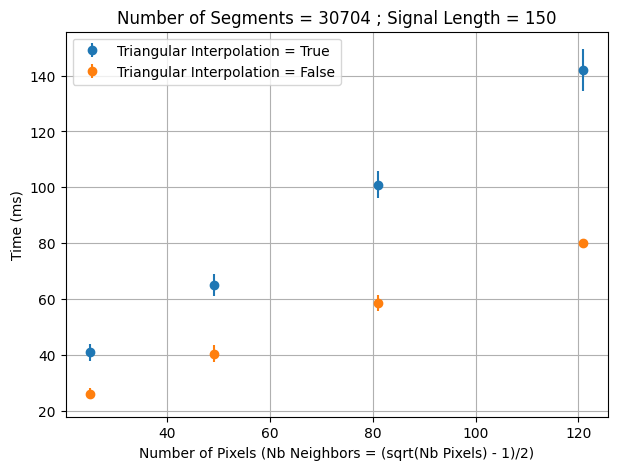

In [26]:
from dataclasses import dataclass

@dataclass
class TimingResult:
    nb_segments: int
    nb_pixels: int
    signal_length: int
    time: float
    error: float
    triangular_interpolation: bool = True

results = []

results.append(TimingResult(30704, 4, 150, 101, 4.92))
results.append(TimingResult(60619, 4, 150, 268, 11))
results.append(TimingResult(90770, 4, 150, 482, 23))
results.append(TimingResult(120812, 4, 150, 737, 34))
results.append(TimingResult(150991, 4, 150, 853, 38))
results.append(TimingResult(201171, 4, 150, 1090, 50))

results.append(TimingResult(30704, 4, 50, 47, 3.34))
results.append(TimingResult(30704, 4, 100, 70, 4.6))
results.append(TimingResult(30704, 4, 200, 142, 8))
results.append(TimingResult(30704, 3, 150, 65, 3.85))
results.append(TimingResult(30704, 2, 150, 41, 3))
results.append(TimingResult(30704, 5, 150, 142, 7.42))

results.append(TimingResult(30704, 5, 150, 80, 1.43, False))
results.append(TimingResult(30704, 4, 150, 58.6, 3, False))
results.append(TimingResult(30704, 3, 150, 40.5, 3, False))
results.append(TimingResult(30704, 2, 150, 26.2, 2, False))
results.append(TimingResult(30704, 4, 200, 78.3, 4.3, False))
results.append(TimingResult(30704, 4, 100, 43.2, 2.75, False))
results.append(TimingResult(30704, 4, 50, 32.1, 2.52, False))

results.append(TimingResult(60619, 4, 150, 147, 5, False))
results.append(TimingResult(90770, 4, 150, 264, 12, False))
results.append(TimingResult(120812, 4, 150, 401, 17, False))
results.append(TimingResult(150991, 4, 150, 473, 19, False))
results.append(TimingResult(201171, 4, 150, 607, 25, False))
    
plt.figure(figsize=(7, 5))
plt.errorbar([r.nb_segments for r in results if (r.signal_length == 150) & (r.triangular_interpolation) & (r.nb_pixels == 4)], [r.time for r in results if (r.signal_length == 150) & (r.triangular_interpolation) & (r.nb_pixels == 4)], yerr=[r.error for r in results if (r.signal_length == 150) & (r.triangular_interpolation) & (r.nb_pixels == 4)], fmt='o', label='Triangular Interpolation = True')
plt.errorbar([r.nb_segments for r in results if (r.signal_length == 150) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], [r.time for r in results if (r.signal_length == 150) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], yerr=[r.error for r in results if (r.signal_length == 150) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], fmt='o', label='Triangular Interpolation = False')
plt.xlabel('Number of Segments')
plt.ylabel('Time (ms)')
plt.legend()
plt.title('Signal Length = 150 ; Nb Pixels = 9x9')
plt.grid()

plt.figure(figsize=(7, 5))
plt.errorbar([r.signal_length for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.nb_pixels == 4)], [r.time for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.nb_pixels == 4)], yerr=[r.error for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.nb_pixels == 4)], fmt='o', label='Triangular Interpolation = True')
plt.errorbar([r.signal_length for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], [r.time for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], yerr=[r.error for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.nb_pixels == 4)], fmt='o', label='Triangular Interpolation = False')
plt.xlabel('Signal Length (ticks)')
plt.ylabel('Time (ms)')
plt.legend()
plt.title('Number of Segments = 30704 ; Nb Pixels = 9x9')
plt.grid()

plt.figure(figsize=(7, 5))
plt.errorbar([(2*r.nb_pixels + 1)**2 for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.signal_length == 150)], [r.time for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.signal_length == 150)], yerr=[r.error for r in results if (r.nb_segments == 30704) & (r.triangular_interpolation) & (r.signal_length == 150)], fmt='o', label='Triangular Interpolation = True')
plt.errorbar([(2*r.nb_pixels + 1)**2 for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.signal_length == 150)], [r.time for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.signal_length == 150)], yerr=[r.error for r in results if (r.nb_segments == 30704) & (not r.triangular_interpolation) & (r.signal_length == 150)], fmt='o', label='Triangular Interpolation = False')
plt.xlabel('Number of Pixels (Nb Neighbors = (sqrt(Nb Pixels) - 1)/2)')
plt.ylabel('Time (ms)')
plt.legend()
plt.title('Number of Segments = 30704 ; Signal Length = 150')
plt.grid()